In [ ]:
import pandas as pd
import numpy as np

In [ ]:
movie = pd.read_csv('/content/movies.csv')
ratings = pd.read_csv('/content/ratings.csv')

In [ ]:
movie.head(4)

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance


In [ ]:
ratings.head(4)

,userId,movieId,rating,timestamp
0,1,296.0,5.0,1.147880e+09
1,1,306.0,3.5,1.147869e+09
2,1,307.0,5.0,1.147869e+09
3,1,665.0,5.0,1.147879e+09


In [ ]:
print(movie.shape)
print(ratings.shape)

(62423, 3)
(25037836, 4)


In [ ]:
movie.isnull().sum()

,0
movieId,0
title,0
genres,0


In [ ]:
ratings.isnull().sum()

,0
userId,0
movieId,0
rating,0
timestamp,1


In [ ]:
movie.duplicated().sum()

0

In [ ]:
ratings.duplicated().sum()

37740

/tmp/ipykernel_29726/1773946770.py:6: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  merged_df = pd.merge(movie, ratings, on='movieId')


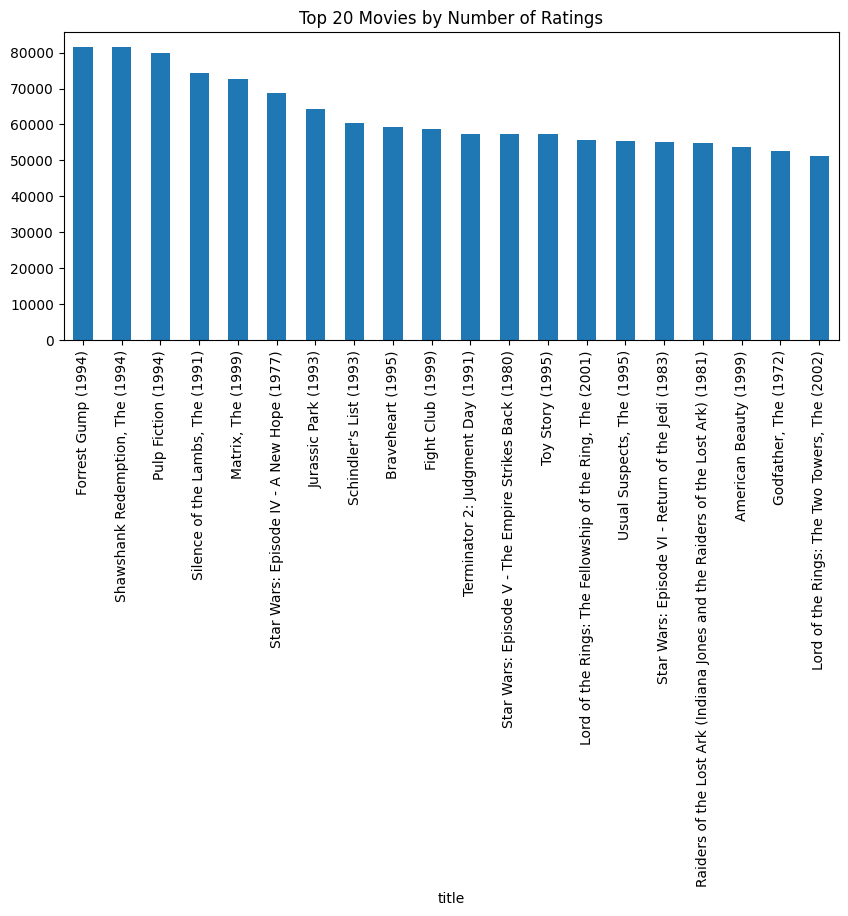

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,4))
# Merge the movie and ratings dataframes
merged_df = pd.merge(movie, ratings, on='movieId')
# Group by title and count the 'rating' column
merged_df.groupby('title')['rating'].count().sort_values(ascending=False).head(20).plot(kind='bar')
plt.title('Top 20 Movies by Number of Ratings')
plt.show()

In [ ]:
n_ratings = len(ratings)
n_movies = len(ratings['movieId'].unique())
n_users = len(ratings['userId'].unique())

sparsity = 1 - (n_ratings / (n_movies * n_users))
print(f"Sparsity: {sparsity * 100:.2f}%")

Sparsity: 99.74%


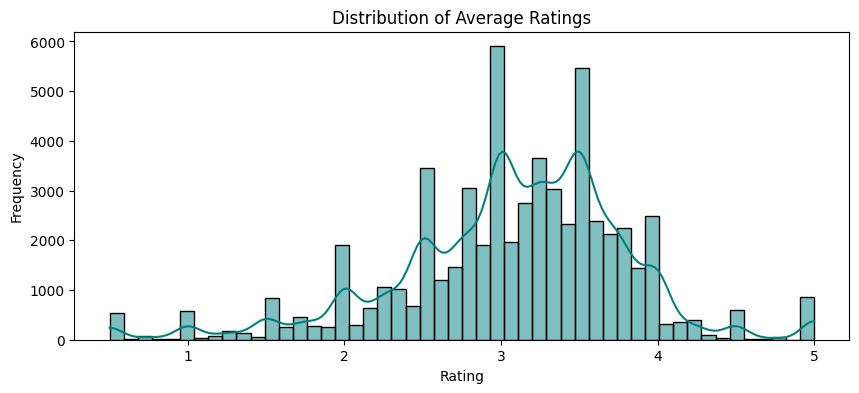

In [ ]:
# Calculate average rating and number of ratings for each movie
movie_stats = merged_df.groupby('title')['rating'].agg(['mean', 'count'])

plt.figure(figsize=(10,4))
sns.histplot(movie_stats['mean'], bins=50, kde=True, color='teal')
plt.title('Distribution of Average Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

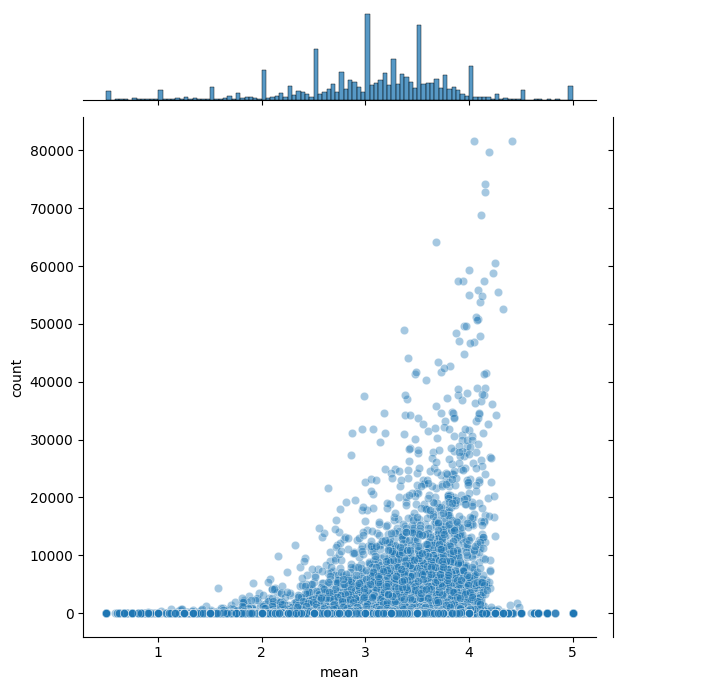

In [ ]:
sns.jointplot(x='mean', y='count', data=movie_stats, alpha=0.4, height=7)
plt.show()

/tmp/ipykernel_29726/2551143869.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='genres', data=genres_df, order=genres_df['genres'].value_counts().index, palette='viridis')


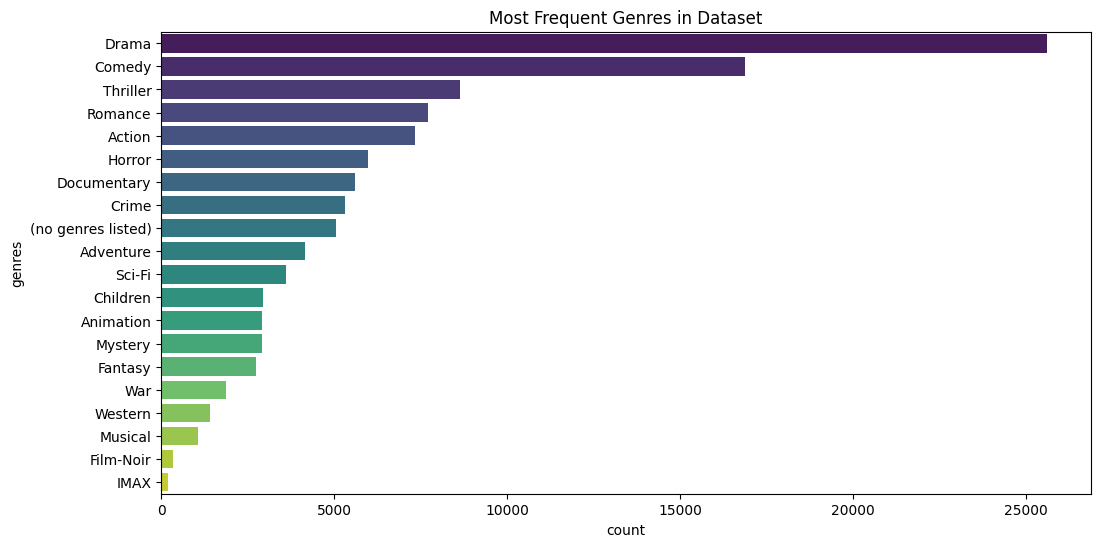

In [ ]:
# Split and explode the genres
genres_df = movie.copy()
genres_df['genres'] = genres_df['genres'].str.split('|')
genres_df = genres_df.explode('genres')

plt.figure(figsize=(12,6))
sns.countplot(y='genres', data=genres_df, order=genres_df['genres'].value_counts().index, palette='viridis')
plt.title('Most Frequent Genres in Dataset')
plt.show()

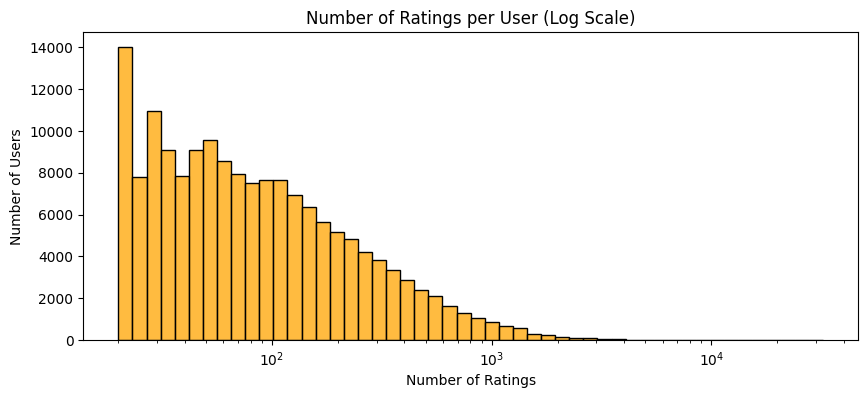

Average ratings per user: 154.04
Median ratings per user: 71.0


In [ ]:
user_counts = ratings.groupby('userId')['rating'].count()

plt.figure(figsize=(10,4))
sns.histplot(user_counts, bins=50, log_scale=True, color='orange')
plt.title('Number of Ratings per User (Log Scale)')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Users')
plt.show()

print(f"Average ratings per user: {user_counts.mean():.2f}")
print(f"Median ratings per user: {user_counts.median()}")

Popular based Recommender System

In [ ]:
# 1. Calculate the components
v = movie_stats['count']
R = movie_stats['mean']
C = movie_stats['mean'].mean()
m = movie_stats['count'].quantile(0.90) # Only movies in the top 10% of popularity

# 2. Apply the formula
movie_stats['weighted_score'] = (v/(v+m) * R) + (m/(v+m) * C)

# 3. Sort and display top 10
popular_movies = movie_stats.sort_values('weighted_score', ascending=False)
print(f"Minimum ratings required (m): {int(m)}")
popular_movies[['weighted_score', 'count', 'mean']].head(10)

Minimum ratings required (m): 415


,weighted_score,count,mean
title,,,
"Shawshank Redemption, The (1994)",4.406641,81622,4.413430
"Godfather, The (1972)",4.314438,52591,4.324247
"Usual Suspects, The (1995)",4.275303,55453,4.284313
"Godfather: Part II, The (1974)",4.247572,34242,4.261828
Schindler's List (1993),4.239709,60528,4.247720
Fight Club (1999),4.220032,58870,4.228130
Seven Samurai (Shichinin no samurai) (1954),4.218986,13390,4.254556
Rear Window (1954),4.214527,20189,4.238026
12 Angry Men (1957),4.214519,16598,4.243102


In [ ]:
def get_popular_recommendations(genre=None, top_n=10):
    if genre:
        # Filter movies by specific genre first
        genre_movies = genres_df[genres_df['genres'] == genre]['title']
        subset = movie_stats[movie_stats.index.isin(genre_movies)]
    else:
        subset = movie_stats

    return subset.sort_values('weighted_score', ascending=False).head(top_n)



In [ ]:
get_popular_recommendations(genre='Drama')

,mean,count,weighted_score
title,,,
"Shawshank Redemption, The (1994)",4.413430,81622,4.406641
"Godfather, The (1972)",4.324247,52591,4.314438
"Godfather: Part II, The (1974)",4.261828,34242,4.247572
Schindler's List (1993),4.247720,60528,4.239709
Fight Club (1999),4.228130,58870,4.220032
Seven Samurai (Shichinin no samurai) (1954),4.254556,13390,4.218986
12 Angry Men (1957),4.243102,16598,4.214519
One Flew Over the Cuckoo's Nest (1975),4.218587,36116,4.205554
Casablanca (1942),4.206657,26936,4.189430


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the vectorizer
tfidf = TfidfVectorizer(stop_words='english')

# Replace NaN if any and fit/transform the genres
movie['genres'] = movie['genres'].fillna('')
tfidf_matrix = tfidf.fit_transform(movie['genres'])

print(f"Matrix Shape: {tfidf_matrix.shape}")

Matrix Shape: (62423, 23)


In [ ]:
from sklearn.metrics.pairwise import linear_kernel

# Create the index mapping as usual
indices = pd.Series(movie.index, index=movie['title']).drop_duplicates()



In [ ]:
def get_content_recommendations(title, tfidf_matrix=tfidf_matrix):
    if title not in indices:
        return "Movie not found."

    # Get the index of the movie
    idx = indices[title]

    # ONLY calculate similarity for this specific movie against all others
    # This is a (1, 62423) vector instead of a (62423, 62423) matrix
    sim_scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()

    # Get indices of the top 10 similar movies
    # We use argpartition for faster sorting of just the top 11 elements
    related_docs_indices = np.argpartition(sim_scores, -11)[-11:]

    # Sort them properly and remove the input movie itself
    recommended_indices = related_docs_indices[np.argsort(sim_scores[related_docs_indices])[::-1]]
    recommended_indices = [i for i in recommended_indices if i != idx]

    return movie['title'].iloc[recommended_indices[:10]]

In [ ]:
get_content_recommendations('Toy Story (1995)')

,title
30348,The Good Dinosaur (2015)
22633,Toy Story Toons: Hawaiian Vacation (2011)
30472,Scooby-Doo! Mask of the Blue Falcon (2012)
43614,Moana (2016)
11604,Shrek the Third (2007)
17431,Asterix and the Vikings (Astérix et les Viking...
4780,"Monsters, Inc. (2001)"
22353,"Boxtrolls, The (2014)"
59328,Wonder Park (2019)
52826,Tangled: Before Ever After (2017)


In [ ]:
!pip install scikit-surprise

In [ ]:
# First, uninstall the current numpy and install a compatible version
!pip uninstall numpy -y
!pip install 'numpy<2'

from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy

# Define a Reader object with the rating scale (1-5 in your dataset)
reader = Reader(rating_scale=(0.5, 5.0))

# Load the ratings data from your existing dataframe
# Surprise expects columns in this order: [userID, itemID, rating]
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

# Split into training and testing sets
trainset, testset = train_test_split(data, test_size=0.2)

Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.51.0 